# Project 2: Data Classification Using AI

This notebook demonstrates a complete workflow for loading a dataset, preprocessing features, training a simple classification model, and evaluating its performance.

## Step 1: Load and Understand the Dataset
First, we will load the diabetes dataset and perform a basic exploratory analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for plots
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv('diabetes.csv')

# Display the first few rows
print("First 5 rows of the dataset:")
display(df.head())

# Print basic dataset information
print("\nDataset shape:", df.shape)
print("\nSummary statistics:")
display(df.describe())

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

First 5 rows of the dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset shape: (768, 9)

Summary statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## Step 2: Split Data into Training and Testing Sets
We will separate the target variable (`Outcome`) from the feature columns, and then split the dataset into 80% training and 20% testing sets.

In [2]:
from sklearn.model_selection import train_test_split

# Define features and target
X = df.drop(columns=['Outcome'])
y = df['Outcome']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (614, 8)
Testing set shape: (154, 8)


## Step 3: Apply a Simple Classification Algorithm
We will use Logistic Regression as our classification model. Since Logistic Regression is sensitive to feature scaling, we will standardize the features using `StandardScaler` first.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# Create a pipeline with StandardScaler and LogisticRegression
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

# Train the model
model.fit(X_train, y_train)
print("Model trained successfully!")

Model trained successfully!


## Step 4: Evaluate the Model
We will predict the classes for the test dataset and compute accuracy, classification report, and plot the confusion matrix.

In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict outcomes
y_pred = model.predict(X_test)

# Print accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}")

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy Score: 0.7143

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.82      0.79       100
           1       0.61      0.52      0.56        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154



### Plot Confusion Matrix using Seaborn

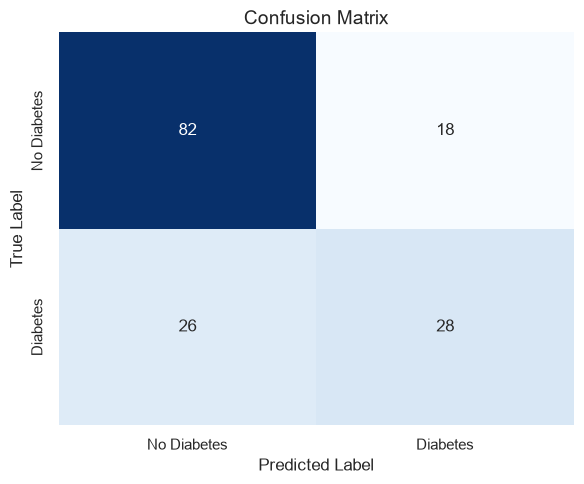

In [5]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.title('Confusion Matrix', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

## Step 5: Plot AUC-ROC Curve and Print Area Under the Curve (AUC)
The Area Under the Receiver Operating Characteristic Curve (ROC AUC) measures the classifier's ability to distinguish between classes.

Area Under the ROC Curve (AUC Score): 0.8230


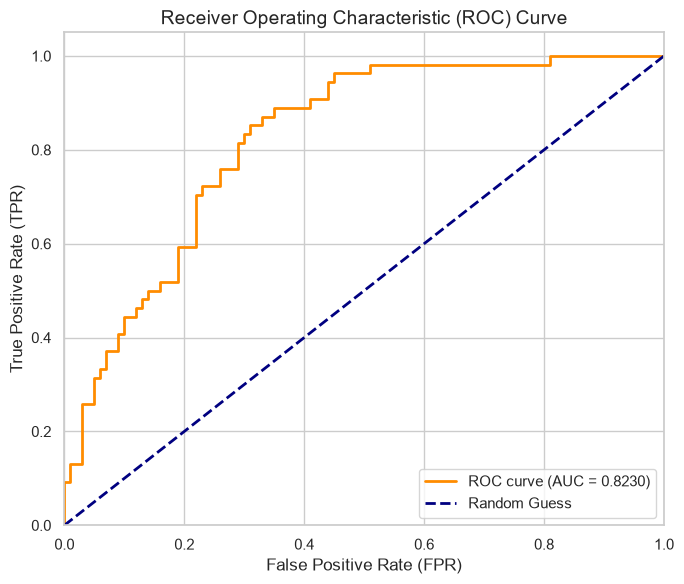

In [6]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get prediction probabilities for the positive class (Diabetes)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve details
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC Score
auc_score = roc_auc_score(y_test, y_prob)
print(f"Area Under the ROC Curve (AUC Score): {auc_score:.4f}")

# Plot AUC-ROC Curve
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()